# 09 · Tuning and ensemble models

**Question.** The production model (XGBoost, notebook 06) scored ROC-AUC 0.804. Can wider, properly cross-validated tuning and a blend of different model types do better, and does the gain survive a month-by-month test?

**How this notebook works.** The heavy lifting lives in `src/tuning.py`, `src/ensemble.py` and `train_ensemble.py` (about 17 minutes on one CPU core). This notebook reads what that script saved (`dashboard/ensemble_report.json` and the trial tables) and shows it. To re-run everything, use `train_ensemble.bat` or `python train_ensemble.py`.

**Protocol (fixed before looking at test results)**
1. Same stratified 80/20 split as notebooks 05 to 08 (`random_state=42`).
2. Tune by 3-fold CV on the training rows only. The production settings are trial 0, so "did tuning help?" is answered on identical folds.
3. Blend weights and alert thresholds are chosen on out-of-fold predictions of the training rows.
4. Test rows are scored once.
5. A monthly retrain-and-predict backtest decides whether the blend is served.

In [1]:
import json, os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
rep = json.load(open(os.path.join(ROOT, 'dashboard', 'ensemble_report.json')))
print('Report generated', rep['generated_utc'], '| quick run:', rep['quick_run'], '| runtime', rep['runtime_minutes'], 'min')

Report generated 2026-10-22T08:12:52+00:00 | quick run: False | runtime 16.6 min


## 1. Tuning

Random search (Bergstra & Bengio, 2012) over wide ranges for XGBoost and histogram gradient boosting. Every trial is kept.

XGBoost: 25 trials. Current settings: CV ROC-AUC 0.7971. Best found: 0.7995. Median trial: 0.7939
Histogram boosting: 10 trials. Best CV ROC-AUC 0.7980


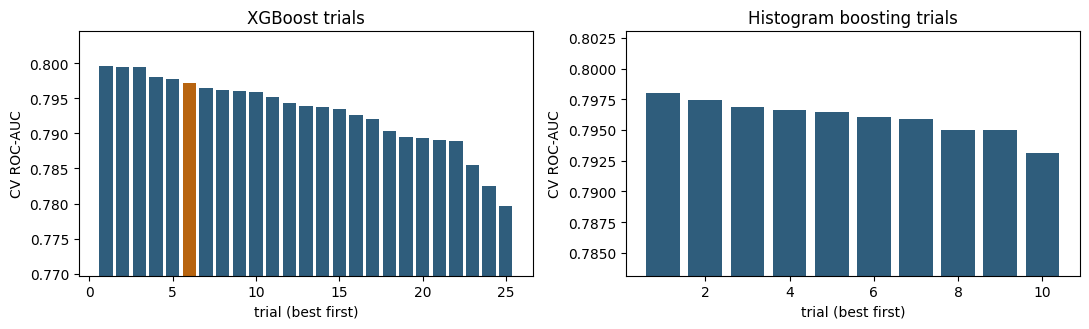

Best XGBoost settings:
{
 "colsample_bytree": 0.811649,
 "gamma": 0.6617959999999999,
 "learning_rate": 0.023152,
 "max_depth": 9,
 "min_child_weight": 5,
 "n_estimators": 248,
 "reg_alpha": 0.153884,
 "reg_lambda": 1.377497,
 "subsample": 0.8244969999999999
}


In [2]:
xt = pd.read_csv(os.path.join(ROOT, 'data', 'processed', 'tuning_trials_xgb.csv'))
ht = pd.read_csv(os.path.join(ROOT, 'data', 'processed', 'tuning_trials_hgb.csv'))
base = xt[xt.kind == 'baseline'].iloc[0]
print(f"XGBoost: {len(xt)} trials. Current settings: CV ROC-AUC {base.cv_roc_auc:.4f}. Best found: {xt.cv_roc_auc.max():.4f}. Median trial: {xt.cv_roc_auc.median():.4f}")
print(f"Histogram boosting: {len(ht)} trials. Best CV ROC-AUC {ht.cv_roc_auc.max():.4f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, t, title in ((ax[0], xt, 'XGBoost trials'), (ax[1], ht, 'Histogram boosting trials')):
    a.bar(range(1, len(t) + 1), t.cv_roc_auc, color=['#b8640f' if k == 'baseline' else '#2f5d7c' for k in t.kind])
    a.set_ylim(max(0.7, t.cv_roc_auc.min() - 0.01), t.cv_roc_auc.max() + 0.005); a.set_title(title); a.set_xlabel('trial (best first)'); a.set_ylabel('CV ROC-AUC')
plt.tight_layout(); plt.show()
print('Best XGBoost settings:'); print(json.dumps(rep['tuning']['xgb']['best_params'], indent=1))

**Reading it.** Many very different settings land within a few thousandths of each other. That is the signature of a problem limited by the data (what is known at checkout) rather than by the settings. Tuning is worth doing, and worth reporting honestly, but it is not where the big gains are.

## 2. Do the members make different mistakes?

An ensemble helps when its members are each good and not copies of each other (Dietterich, 2000).

In [3]:
oof = pd.Series(rep['oof_auc']).rename('out-of-fold ROC-AUC (train)')
w = pd.Series(rep['weights']).rename('blend weight')
print(pd.concat([oof, w], axis=1).round(4).to_string())
print('\nBlend OOF ROC-AUC:', rep['oof_blend_auc'], '| stacked meta-learner OOF:', round(rep['stack']['roc_auc'], 4))

     out-of-fold ROC-AUC (train)  blend weight
xgb                       0.8020          0.55
hgb                       0.8006          0.40
lr                        0.7131          0.05
rf                        0.7631          0.00

Blend OOF ROC-AUC: 0.8074 | stacked meta-learner OOF: 0.8069


The search over weights (a grid, on out-of-fold training predictions) gives the random forest zero weight and logistic regression a token 5%: they are individually weaker and mostly repeat what the boosted models already know. A stacked meta-learner scores about the same, but it outputs calibrated probabilities (around 8% for a typical order), which would break the app's risk bands at 30/60/80%. So the served blend is a plain weighted average of class-balanced models, which keeps the probability scale the rest of OnTime is built on.

## 3. Test-set comparison (scored once)

In [4]:
rows = []
for r in rep['models']:
    rows.append({'model': r['label'], 'ROC-AUC': r['roc_auc'], 'PR-AUC': r['pr_auc'], 'precision': r['precision'], 'recall': r['recall'], 'F1': r['f1'], 'late orders in top 10%': r['recall_at_top10pct'], 'served': r['served']})
tab = pd.DataFrame(rows).set_index('model').round(4); display(tab)

,ROC-AUC,PR-AUC,precision,recall,F1,late orders in top 10%,served
model,,,,,,,
XGBoost - current production model,0.8041,0.3361,0.3110,0.4831,0.3784,0.4230,False
XGBoost - re-tuned (wider search),0.8070,0.3433,0.3122,0.4971,0.3835,0.4390,False
Histogram gradient boosting - tuned,0.8019,0.3300,0.3117,0.4901,0.3810,0.4192,False
Logistic regression,0.7101,0.1864,0.1741,0.4543,0.2517,0.2799,False
Random forest,0.7601,0.2832,0.2918,0.4281,0.3471,0.3885,False
Weighted ensemble (blend),0.8094,0.3429,0.3319,0.4786,0.3919,0.4390,True


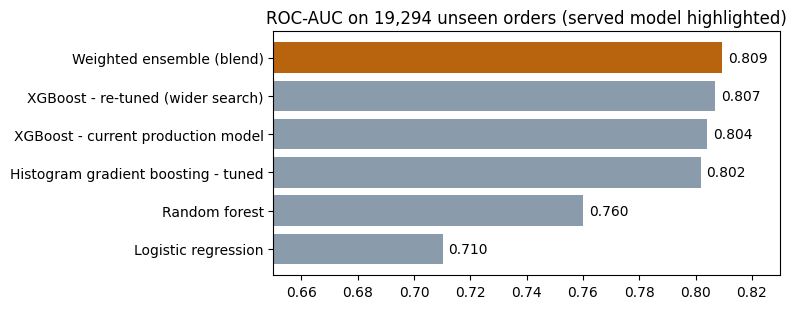

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
t = tab.sort_values('ROC-AUC'); ax.barh(t.index, t['ROC-AUC'], color=['#b8640f' if s else '#8a9bab' for s in t.served]); ax.set_xlim(0.65, 0.83)
for i, v in enumerate(t['ROC-AUC']): ax.text(v + 0.002, i, f'{v:.3f}', va='center')
ax.set_title('ROC-AUC on 19,294 unseen orders (served model highlighted)'); plt.tight_layout(); plt.show()

## 4. Does it hold up month after month?

Retrain on everything before a month, predict that month, repeat (17 months). This is how the system is meant to be run, and the Olist late rate swings with the season, so it is the harder and more honest test.

production_xgb    0.6615
xgb_tuned         0.6639
blend             0.6799


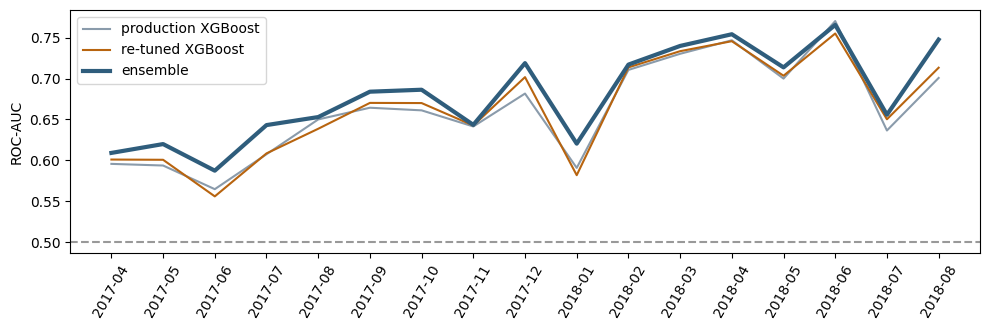

Ensemble minus production XGBoost: mean +0.0184 ROC-AUC; ahead in 16 of 17 months. Random split difference: +0.0053.


In [6]:
bt = {k: pd.DataFrame(v).set_index('month')['auc'] for k, v in rep['backtest'].items()}
bt = pd.DataFrame(bt); print(bt.mean().round(4).to_string())
fig, ax = plt.subplots(figsize=(10, 3.4))
names = {'production_xgb': 'production XGBoost', 'xgb_tuned': 're-tuned XGBoost', 'blend': 'ensemble'}
for c, col, lw in (('production_xgb', '#8a9bab', 1.5), ('xgb_tuned', '#b8640f', 1.5), ('blend', '#2f5d7c', 3)): ax.plot(bt.index, bt[c], label=names[c], color=col, lw=lw)
ax.axhline(0.5, ls='--', c='#999'); ax.legend(); ax.set_ylabel('ROC-AUC'); plt.xticks(rotation=60); plt.tight_layout(); plt.show()
pb = rep['paired_backtest']
print(f"Ensemble minus production XGBoost: mean {pb['mean_diff']:+.4f} ROC-AUC; ahead in {pb['months_blend_better']} of {pb['months']} months. Random split difference: {pb['test_diff']:+.4f}.")

## 5. Decision

The rule was written into `train_ensemble.py` before the full run: serve the blend only if it is (a) better on the monthly backtest by at least 0.005 ROC-AUC in at least 60% of months **and** (b) no worse than 0.005 on the random test split.

A note on honesty: an earlier 4-trial quick run showed the two tests disagreeing (the blend was slightly lower on the random split, higher on the backtest). The rule above, which makes the backtest the primary test, was settled after seeing that, on the argument that the backtest matches how the system is actually used. The full run then cleared both bars, so the choice of rule did not decide the outcome, but you should know the order of events.

In [7]:
print(rep['decision'])

Random test split: blend 0.8094 vs production XGBoost 0.8041 (difference +0.0053). Monthly backtest: blend 0.6799 vs 0.6615 mean AUC (difference +0.0184, blend better in 16 of 17 months). The blend is served: it clears both bars (better on the monthly backtest by at least 0.005 AUC in at least 60% of months, and no worse than 0.005 AUC on the random split).


## 6. What this does and does not show

* The gain is real but modest on the random split (+0.005 ROC-AUC) and larger on the monthly backtest (+0.018), where the blend wins in 16 of 17 months. Absolute monthly AUC is still only about 0.68: seasonality, not model choice, is the main limit (notebook 06).
* All numbers are on Olist, 2016 to 2018. They say nothing about another company's orders. See the *Adapt to your data* page for how to check that.
* Explanations shown in the app (TreeSHAP) come from the blend's XGBoost member, not from the whole blend.